# Supplementary Figure S4: syllable repetition in starlings

Reads `repetition_data.pkl`, made by Cell R1 of `data_figs` (n = 6 starlings).

* **A, C**: syllable duration and ISI for repeat and non-repeat transitions, mean ± SEM across birds. Brackets: repeat vs non-repeat within each condition, `y ~ repeat + (1 | bird)` fit separately per condition.
* **B, D**: the effect of condition (RegAir − Heliox) for non-repeat and repeat transitions, from `y ~ condition * repeat + (1 | bird)`, with 95% CI. Bracket: the condition × repeat interaction.
* **E**: repeat probability and repeat run length as ratios (RegAir / Heliox) with 95% CI, from GEE models clustered by bird.


In [1]:
# Setup: paths, figure style, data
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import norm

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
FIG_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'repetition_data.pkl')
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'font.size': 15, 'axes.titlesize': 19, 'axes.labelsize': 16,
                     'xtick.labelsize': 15, 'ytick.labelsize': 14, 'legend.fontsize': 15, 'savefig.dpi': 300,
                     'axes.spines.top': False, 'axes.spines.right': False})

rep = pd.read_pickle(DATA_PATH)
# Coded as 0 / 1 so that every coefficient reads directly as RegAir - Heliox (heliox = 0) and
# as repeat - non-repeat (non-repeat = 0).
transitions = rep['transitions'].assign(regair=lambda d: (d['condition'] == 'regair').astype(int),
                                        repeat=lambda d: d['is_repeat'].astype(int))
runs = rep['runs'].assign(regair=lambda d: (d['condition'] == 'regair').astype(int))
timing = transitions[np.isfinite(transitions['duration_s']) & np.isfinite(transitions['isi_s'])]
print(f"{len(transitions)} transitions ({len(transitions) - len(timing)} without a usable time), "
      f"{len(runs)} runs, {transitions['bird'].nunique()} birds")

48653 transitions (0 without a usable time), 37343 runs, 6 birds


In [2]:
# Models
def lme(formula, data, **fit_options):
    """Bird as random intercept."""
    return smf.mixedlm(formula, data, groups=data['bird']).fit(**fit_options)


def combo(fit, weights):
    """Estimate, SE, z, P and 95% CI of a weighted sum of coefficients, e.g. {'regair': 1, 'regair:repeat': 1}."""
    w = np.array([weights.get(name, 0.0) for name in fit.params.index])
    est = float(w @ fit.params.to_numpy())
    se = float(np.sqrt(w @ fit.cov_params().to_numpy() @ w))
    return dict(est=est, se=se, z=est / se, p=2 * norm.sf(abs(est / se)), lo=est - 1.96 * se, hi=est + 1.96 * se)


effects, within = {}, {}
for y in ('duration_s', 'isi_s'):
    # B, D: one model with the interaction, fit by ML as in the original analysis
    m = lme(f'{y} ~ regair * repeat', timing, reml=False, method='lbfgs')
    effects[y] = {'Non-\nrepeat': combo(m, {'regair': 1}),                           # RegAir - Heliox, non-repeats
                  'Repeat': combo(m, {'regair': 1, 'regair:repeat': 1}),             # RegAir - Heliox, repeats
                  'interaction': combo(m, {'regair:repeat': 1})}
    # A, C brackets: repeat vs non-repeat within one condition, with the default fit (REML) the
    # original analysis used; near the boundary another optimiser can land on a slightly different P
    within[y] = {c: combo(lme(f'{y} ~ repeat', timing[timing['condition'] == c]), {'repeat': 1})
                 for c in ('heliox', 'regair')}


def gee_ratio(formula, data, family):
    """RegAir / Heliox ratio from a GEE clustered by bird (exchangeable working correlation)."""
    fit = smf.gee(formula, groups='bird', data=data, family=family, cov_struct=sm.cov_struct.Exchangeable()).fit()
    b, se = fit.params['regair'], fit.bse['regair']
    return dict(est=np.exp(b), lo=np.exp(b - 1.96 * se), hi=np.exp(b + 1.96 * se), p=fit.pvalues['regair'])


# E: odds ratio of a self-repeat (all transitions), and rate ratio of run length (runs longer than one)
structure = {'P(self-repeat)': gee_ratio('repeat ~ regair', transitions, sm.families.Binomial()),
             'Run length': gee_ratio('run_length ~ regair', runs[runs['run_length'] > 1], sm.families.Poisson())}

table = pd.DataFrame([dict(panel=p, term=k.replace('\n', ''), **{c: v[c] for c in ('est', 'lo', 'hi', 'p')})
                      for p, y in (('B', 'duration_s'), ('D', 'isi_s')) for k, v in effects[y].items()]
                     + [dict(panel='E', term=k, **v) for k, v in structure.items()])
print(table.to_string(index=False, float_format=lambda v: f'{v:.4g}'))

/home/AD/lstanwic/anaconda3/lib/python3.8/site-packages/statsmodels/regression/mixed_linear_model.py:1635: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/home/AD/lstanwic/anaconda3/lib/python3.8/site-packages/statsmodels/regression/mixed_linear_model.py:2238: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/AD/lstanwic/anaconda3/lib/python3.8/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/AD/lstanwic/anaconda3/lib/python3.8/site-packages/statsmodels/regression/mixed_linear_model.py:2201: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/AD/lstanwic/anaconda3/lib/python3.8/site-packages/statsmodels/regression/mixed_linear_model.py:2238: ConvergenceWarning: The MLE may be on the boundary of the parameter 

panel           term      est        lo        hi         p
    B     Non-repeat 0.009194 0.0008715   0.01752   0.03037
    B         Repeat   0.0956   0.08329    0.1079 2.643e-52
    B    interaction   0.0864   0.07217    0.1006 1.226e-32
    D     Non-repeat -0.07641  -0.09459  -0.05823 1.748e-16
    D         Repeat -0.03158  -0.05846 -0.004693   0.02133
    D    interaction  0.04483   0.01375   0.07591    0.0047
    E P(self-repeat)   0.9941    0.8037      1.23    0.9563
    E     Run length    1.048    0.9568     1.148    0.3134


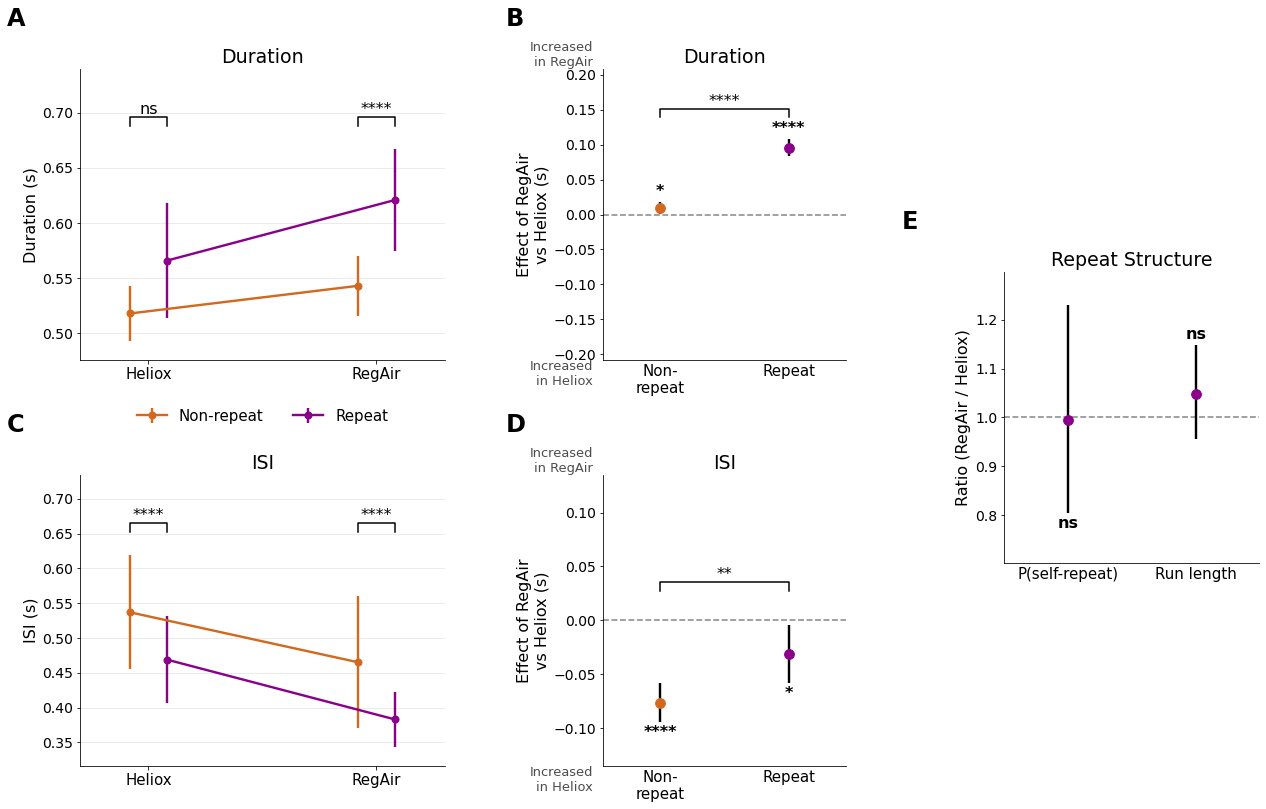

In [3]:
# Supplementary Figure S4
COLOURS = {'Non-repeat': 'chocolate', 'Repeat': 'darkmagenta'}
TITLES = {'duration_s': 'Duration', 'isi_s': 'ISI'}


def stars(p):
    return '****' if p < 1e-4 else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns'


def bracket(ax, x1, x2, y, h, text):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color='black', lw=1.5, clip_on=False)
    ax.text((x1 + x2) / 2, y + h, text, ha='center', va='bottom', fontsize=16, clip_on=False)


def star_at_ci(ax, x, est, lo, hi, ref, p):
    """Stars beyond the end of the CI that points away from the reference line."""
    above = est >= ref
    ax.annotate(stars(p), (x, hi if above else lo), xytext=(0, 3 if above else -3), textcoords='offset points',
                ha='center', va='bottom' if above else 'top', fontsize=16, fontweight='bold')


def panel_means(ax, y):
    """A, C: mean across birds of each bird's mean, for repeat and non-repeat transitions."""
    per_bird = timing.groupby(['bird', 'condition', 'repeat'])[y].mean().reset_index()
    xs = {'heliox': 0, 'regair': 1}
    tops = {}
    for rep_value, name, dx in [(0, 'Non-repeat', -0.08), (1, 'Repeat', 0.08)]:
        s = per_bird[per_bird['repeat'] == rep_value].groupby('condition')[y].agg(['mean', 'sem']).loc[list(xs)]
        ax.errorbar(np.array([0, 1]) + dx, s['mean'], yerr=s['sem'], fmt='o-', lw=2.4, ms=7,
                    color=COLOURS[name], label=name, zorder=3)
        for c in xs:
            tops[c] = max(tops.get(c, -np.inf), s.loc[c, 'mean'] + s.loc[c, 'sem'])
    lows = per_bird.groupby(['condition', 'repeat'])[y].agg(lambda v: v.mean() - v.sem()).min()
    span = max(tops.values()) - lows
    base = max(tops.values()) + 0.12 * span
    for c, x in xs.items():
        bracket(ax, x - 0.08, x + 0.08, base, 0.05 * span, stars(within[y][c]['p']))
    ax.set_ylim(lows - 0.1 * span, base + 0.3 * span)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Heliox', 'RegAir'])
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylabel(f'{TITLES[y]} (s)')
    ax.set_title(TITLES[y])
    ax.grid(axis='y', color='0.9')
    ax.set_axisbelow(True)


def panel_effects(ax, y):
    """B, D: RegAir - Heliox for non-repeat and repeat transitions, 95% CI; bracket = interaction."""
    rows = [(k, v) for k, v in effects[y].items() if k != 'interaction']
    xs = np.array([0.42, 1.14])
    ax.axhline(0, ls='--', lw=1.6, color='0.55', zorder=1)
    for x, (name, e) in zip(xs, rows):
        ax.vlines(x, e['lo'], e['hi'], color='black', lw=2.4, zorder=2)
        ax.scatter(x, e['est'], s=95, color=COLOURS[name.replace('\n', '')], zorder=3)
        star_at_ci(ax, x, e['est'], e['lo'], e['hi'], 0, e['p'])
    lo, hi = min(e['lo'] for _, e in rows), max(e['hi'] for _, e in rows)
    span = hi - lo
    base = max(hi, 0) + 0.3 * span
    bracket(ax, xs[0], xs[1], base, 0.1 * span, stars(effects[y]['interaction']['p']))
    half = 1.25 * max(base + 0.25 * span, abs(min(lo, 0)) + 0.15 * span)       # zero line in the middle
    ax.set_ylim(-half, half)
    ax.set_xlim(0.1, 1.46)
    ax.set_xticks(xs)
    ax.set_xticklabels([name for name, _ in rows])
    ax.tick_params(axis='x', length=0)
    ax.set_ylabel('Effect of RegAir\nvs Heliox (s)')
    ax.set_title(TITLES[y])
    ax.text(-0.04, 1.0, 'Increased\nin RegAir', transform=ax.transAxes, ha='right', va='bottom', fontsize=13, color='0.3')
    ax.text(-0.04, 0.0, 'Increased\nin Heliox', transform=ax.transAxes, ha='right', va='top', fontsize=13, color='0.3')


def panel_structure(ax):
    """E: RegAir / Heliox ratios with 95% CI."""
    ax.axhline(1, ls='--', lw=1.6, color='0.55', zorder=1)
    for x, (name, e) in zip([0.45, 1.35], structure.items()):
        ax.vlines(x, e['lo'], e['hi'], color='black', lw=2.4, zorder=2)
        ax.scatter(x, e['est'], s=95, color='darkmagenta', zorder=3)
        star_at_ci(ax, x, e['est'], e['lo'], e['hi'], 1, e['p'])
    half = 1.3 * max(max(abs(e['hi'] - 1), abs(e['lo'] - 1)) for e in structure.values())
    ax.set_ylim(1 - half, 1 + half)
    ax.set_xlim(0, 1.8)
    ax.set_xticks([0.45, 1.35])
    ax.set_xticklabels(list(structure))
    ax.tick_params(axis='x', length=0)
    ax.set_ylabel('Ratio (RegAir / Heliox)')
    ax.set_title('Repeat Structure')


fig = plt.figure(figsize=(18, 11))
grid = fig.add_gridspec(4, 3, width_ratios=[1.5, 1, 1.05], left=0.07, right=0.98, bottom=0.07, top=0.95,
                        wspace=0.55, hspace=1.3)
axes = {'A': fig.add_subplot(grid[0:2, 0]), 'B': fig.add_subplot(grid[0:2, 1]),
        'C': fig.add_subplot(grid[2:4, 0]), 'D': fig.add_subplot(grid[2:4, 1]),
        'E': fig.add_subplot(grid[1:3, 2])}
panel_means(axes['A'], 'duration_s')
panel_effects(axes['B'], 'duration_s')
panel_means(axes['C'], 'isi_s')
panel_effects(axes['D'], 'isi_s')
panel_structure(axes['E'])
axes['A'].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
for letter, ax in axes.items():
    # above the 'Increased in ...' labels of B and D
    ax.text(-0.2 if letter in 'AC' else -0.4, 1.13, letter, transform=ax.transAxes, fontsize=24,
            fontweight='bold', va='bottom')

fig.savefig(os.path.join(FIG_DIR, 'supp_fig_S4_repetition.png'), bbox_inches='tight')
fig.savefig(os.path.join(FIG_DIR, 'supp_fig_S4_repetition.pdf'), bbox_inches='tight')
plt.show()